In [12]:

# DOCUMIND AI - CPU ENVIRONMENT SETUP

%pip install -q \
    pymupdf \
    sentence-transformers \
    faiss-cpu \
    transformers \
    accelerate \
    gradio \
    sentencepiece

print("All dependencies installed successfully!")


All dependencies installed successfully!


In [13]:

import torch
import platform
import psutil

print("DOCUMIND AI - SYSTEM CHECK")
print("-" * 40)

print("Python:", platform.python_version())
print("Processor:", platform.processor())
print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

print("GPU:", torch.cuda.is_available())

torch.set_num_threads(2)

assert not torch.cuda.is_available(), "GPU detected unexpectedly!"

print("\nCPU environment ready!")


DOCUMIND AI - SYSTEM CHECK
----------------------------------------
Python: 3.13.18
Processor: x86_64
Available RAM: 9.08 GB
GPU: False

CPU environment ready!


In [14]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

print("Model libraries imported successfully!")


Model libraries imported successfully!


In [15]:

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

print("Downloading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Downloading Qwen model...")

llm = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
)

llm.to("cpu")
llm.eval()

print("\nQWEN MODEL LOADED SUCCESSFULLY!")
print("Device: CPU")


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


QWEN MODEL LOADED SUCCESSFULLY!
Device: CPU


In [16]:

messages = [
    {
        "role": "user",
        "content": "You are DocuMind AI. Explain what a RAG system does in three sentences."
    }
]

prompt = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(prompt, return_tensors="pt")

with torch.inference_mode():
    outputs = llm.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

answer = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print("DOCUMIND AI RESPONSE")
print("=" * 50)
print(answer)


DOCUMIND AI RESPONSE
A RAG system stands for "Reinforcement Learning with Generative Adversarial Networks." It is an advanced machine learning model designed to simulate human decision-making processes and generate new ideas or solutions based on the feedback from previous iterations of the same model. In simpler terms, it's a type of artificial intelligence that uses algorithms to learn from data and improve its performance over time, much like how humans learn through trial and error. The term "RAG" refers to Reinforcement Learning (RL), which is a subset of machine learning where the goal is to maximize rewards or minimize penalties during the training


In [17]:

from google.colab import files
import fitz

print("Upload your PDF document")

uploaded = files.upload()

pdf_path = list(uploaded.keys())[0]

print("\nPDF uploaded:", pdf_path)


Upload your PDF document


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving attention-is-all-you-need-1hodz0wcqb.pdf to attention-is-all-you-need-1hodz0wcqb.pdf

PDF uploaded: attention-is-all-you-need-1hodz0wcqb.pdf


In [18]:

def extract_pdf_text(pdf_path):

    document = fitz.open(pdf_path)

    extracted_pages = []

    for page_number, page in enumerate(document, start=1):

        text = page.get_text("text")

        if text.strip():

            extracted_pages.append({
                "page": page_number,
                "text": text.strip()
            })

    return extracted_pages


pages = extract_pdf_text(pdf_path)

print("PDF EXTRACTION REPORT")
print("-" * 40)
print("Total pages:", len(pages))
print("Pages containing text:", len(pages))

print("\nFIRST PAGE PREVIEW:")
print(pages[0]["text"][:1200] if pages else "No text extracted")


PDF EXTRACTION REPORT
----------------------------------------
Total pages: 11
Pages containing text: 11

FIRST PAGE PREVIEW:
Attention Is All You Need
Ashish Vaswani∗
Google Brain
avaswani@google.com
Noam Shazeer∗
Google Brain
noam@google.com
Niki Parmar∗
Google Research
nikip@google.com
Jakob Uszkoreit∗
Google Research
usz@google.com
Llion Jones∗
Google Research
llion@google.com
Aidan N. Gomez∗†
University of Toronto
aidan@cs.toronto.edu
Łukasz Kaiser∗
Google Brain
lukaszkaiser@google.com
Illia Polosukhin∗‡
illia.polosukhin@gmail.com
Abstract
The dominant sequence transduction models are based on complex recurrent or
convolutional neural networks that include an encoder and a decoder. The best
performing models also connect the encoder and decoder through an attention
mechanism. We propose a new simple network architecture, the Transformer,
based solely on attention mechanisms, dispensing with recurrence and convolutions
entirely. Experiments on two machine translation tasks show the

In [19]:

def create_chunks(pages, chunk_size=400, overlap=80):

    chunks = []

    for page in pages:

        words = page["text"].split()

        start = 0

        while start < len(words):

            end = start + chunk_size

            chunk_text = " ".join(words[start:end])

            if chunk_text.strip():

                chunks.append({
                    "text": chunk_text,
                    "page": page["page"]
                })

            start += chunk_size - overlap

    return chunks


chunks = create_chunks(pages)

print("CHUNKING REPORT")
print("-" * 40)
print("Total chunks:", len(chunks))
print("\nFirst chunk:")
print(chunks[0]["text"][:500] if chunks else "No chunks created")


CHUNKING REPORT
----------------------------------------
Total chunks: 20

First chunk:
Attention Is All You Need Ashish Vaswani∗ Google Brain avaswani@google.com Noam Shazeer∗ Google Brain noam@google.com Niki Parmar∗ Google Research nikip@google.com Jakob Uszkoreit∗ Google Research usz@google.com Llion Jones∗ Google Research llion@google.com Aidan N. Gomez∗† University of Toronto aidan@cs.toronto.edu Łukasz Kaiser∗ Google Brain lukaszkaiser@google.com Illia Polosukhin∗‡ illia.polosukhin@gmail.com Abstract The dominant sequence transduction models are based on complex recurrent or


In [20]:

from sentence_transformers import SentenceTransformer

print("Loading Sentence Transformer...")

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cpu"
)

print("Embedding model loaded!")
print("Device: CPU")
print("Dimensions:",
      embedding_model.get_sentence_embedding_dimension())


Loading Sentence Transformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded!
Device: CPU
Dimensions: 384


/tmp/ipykernel_10798/2772733768.py:13: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension())


In [21]:

chunk_texts = [chunk["text"] for chunk in chunks]

embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("\nEMBEDDING REPORT")
print("-" * 40)
print("Total chunks:", len(chunks))
print("Embedding shape:", embeddings.shape)
print("Embedding dimensions:", embeddings.shape[1])


Batches:   0%|          | 0/1 [00:00<?, ?it/s]


EMBEDDING REPORT
----------------------------------------
Total chunks: 20
Embedding shape: (20, 384)
Embedding dimensions: 384


In [22]:

import faiss
import numpy as np

dimension = embeddings.shape[1]

vector_database = faiss.IndexFlatIP(dimension)

vector_database.add(
    embeddings.astype("float32")
)

print("FAISS DATABASE CREATED!")
print("-" * 40)
print("Vectors stored:", vector_database.ntotal)
print("Dimensions:", dimension)


FAISS DATABASE CREATED!
----------------------------------------
Vectors stored: 20
Dimensions: 384


In [23]:

def retrieve_relevant_chunks(query, top_k=3):

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = vector_database.search(
        query_embedding,
        min(top_k, len(chunks))
    )

    results = []

    for score, index in zip(scores[0], indices[0]):

        if index >= 0:

            results.append({
                "text": chunks[index]["text"],
                "page": chunks[index]["page"],
                "similarity": float(score)
            })

    return results


# Test semantic search
results = retrieve_relevant_chunks(
    "Why was the Transformer architecture introduced?",
    top_k=3
)

for i, result in enumerate(results, 1):

    print(f"\nRESULT {i}")
    print("Page:", result["page"])
    print("Similarity:", round(result["similarity"], 4))
    print("Content:", result["text"][:400])
    print("-" * 50)



RESULT 1
Page: 3
Similarity: 0.3549
Content: Figure 1: The Transformer - model architecture. wise fully connected feed-forward network. We employ a residual connection [10] around each of the two sub-layers, followed by layer normalization [1]. That is, the output of each sub-layer is LayerNorm(x + Sublayer(x)), where Sublayer(x) is the function implemented by the sub-layer itself. To facilitate these residual connections, all sub-layers in 
--------------------------------------------------

RESULT 2
Page: 8
Similarity: 0.3158
Content: Table 2: The Transformer achieves better BLEU scores than previous state-of-the-art models on the English-to-German and English-to-French newstest2014 tests at a fraction of the training cost. Model BLEU Training Cost (FLOPs) EN-DE EN-FR EN-DE EN-FR ByteNet [15] 23.75 Deep-Att + PosUnk [32] 39.2 1.0 · 1020 GNMT + RL [31] 24.6 39.92 2.3 · 1019 1.4 · 1020 ConvS2S [8] 25.16 40.46 9.6 · 1018 1.5 · 102
--------------------------------------------------

RES

In [24]:

def ask_documind(question):

    # Retrieve relevant document sections
    retrieved = retrieve_relevant_chunks(
        question,
        top_k=4
    )

    if not retrieved:
        return "No relevant information found."

    # Construct document context
    context = ""

    for item in retrieved:
        context += (
            f"\n[Source: Page {item['page']}]\n"
            f"{item['text']}\n"
        )

    # Create instructions
    messages = [
        {
            "role": "system",
            "content": """
You are DocuMind AI, a research paper assistant.

IMPORTANT:
1. RAG means Retrieval-Augmented Generation.
2. Answer only using the supplied document context.
3. Never invent research findings.
4. If the context does not contain the answer,
   clearly state that the information was not found.
5. Keep answers concise and understandable.
6. Mention the source page numbers.
7. Do not confuse retrieved passages with your own knowledge.
"""
        },
        {
            "role": "user",
            "content": f"""
DOCUMENT CONTEXT:

{context}

QUESTION:
{question}

Answer based only on the document.
"""
        }
    ]

    # Convert messages into model input
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    # Generate answer using CPU
    with torch.inference_mode():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return answer.strip()


print("DocuMind RAG pipeline initialized!")


DocuMind RAG pipeline initialized!


In [25]:

question = "Why did the authors introduce the Transformer architecture?"

answer = ask_documind(question)

print("=" * 60)
print("DOCUMIND AI - RESEARCH ASSISTANT")
print("=" * 60)

print("\nQUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(answer)


DOCUMIND AI - RESEARCH ASSISTANT

QUESTION:
Why did the authors introduce the Transformer architecture?

GENERATED ANSWER:
to continue improving the performance of the Transformer by adding more complex features such as positional embeddings and learning-based positional encodings.


In [27]:

question = "How does the Transformer use attention mechanisms?"

print("QUESTION:", question)
print("\nANSWER:")
print(ask_documind(question))


QUESTION: How does the Transformer use attention mechanisms?

ANSWER:
The Transformer uses attention mechanisms to reduce sequential computation and achieve significant improvements in translation quality after being trained for as little as twelve hours on eight P100 GPUs.


In [28]:

question = "How does the Transformer use attention mechanisms?"

print("QUESTION:", question)
print("\nANSWER:")
print(ask_documind(question))


QUESTION: How does the Transformer use attention mechanisms?

ANSWER:
The Transformer uses attention mechanisms to reduce sequential computation and achieve significant improvements in translation quality after being trained for as little as twelve hours on eight P100 GPUs.


In [29]:

# Smaller, more focused text chunks

def create_improved_chunks(pages, chunk_size=180, overlap=40):

    improved_chunks = []

    for page in pages:
        words = page["text"].split()
        start = 0

        while start < len(words):
            end = start + chunk_size
            text = " ".join(words[start:end])

            if text.strip():
                improved_chunks.append({
                    "text": text,
                    "page": page["page"]
                })

            start += chunk_size - overlap

    return improved_chunks


chunks = create_improved_chunks(pages)

print("Improved chunks:", len(chunks))
print("Average chunk size:",
      round(np.mean([len(c["text"].split()) for c in chunks]), 1),
      "words")


Improved chunks: 40
Average chunk size: 152.2 words


In [30]:

chunk_texts = [chunk["text"] for chunk in chunks]

embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

vector_database = faiss.IndexFlatIP(embeddings.shape[1])

vector_database.add(embeddings.astype("float32"))

print("Updated FAISS database:", vector_database.ntotal)


Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Updated FAISS database: 40


In [31]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(chunk_texts)

print("TF-IDF keyword search initialized!")


TF-IDF keyword search initialized!


In [32]:

def hybrid_retrieve(query, top_k=4):

    # Semantic similarity
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    semantic_scores = cosine_similarity(
        query_embedding,
        embeddings
    )[0]

    # Keyword similarity
    query_vector = tfidf.transform([query])

    keyword_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]

    # Combined ranking
    combined_scores = (
        0.55 * semantic_scores +
        0.45 * keyword_scores
    )

    best_indices = np.argsort(combined_scores)[::-1][:top_k]

    results = []

    for index in best_indices:
        results.append({
            "text": chunks[index]["text"],
            "page": chunks[index]["page"],
            "similarity": float(combined_scores[index]),
            "semantic_score": float(semantic_scores[index]),
            "keyword_score": float(keyword_scores[index])
        })

    return results


print("Hybrid retrieval system ready!")


Hybrid retrieval system ready!


In [33]:

query = "How does the Transformer use attention mechanisms?"

results = hybrid_retrieve(query, top_k=4)

for i, item in enumerate(results, 1):

    print(f"\nRESULT {i}")
    print("Page:", item["page"])
    print("Combined score:", round(item["similarity"], 4))
    print("Semantic score:", round(item["semantic_score"], 4))
    print("Keyword score:", round(item["keyword_score"], 4))
    print("Content:", item["text"][:600])
    print("-" * 60)



RESULT 1
Page: 2
Combined score: 0.3548
Semantic score: 0.6156
Keyword score: 0.036
Content: Transformer follows this overall architecture using stacked self-attention and point-wise, fully connected layers for both the encoder and decoder, shown in the left and right halves of Figure 1, respectively. 3.1 Encoder and Decoder Stacks Encoder: The encoder is composed of a stack of N = 6 identical layers. Each layer has two sub-layers. The ﬁrst is a multi-head self-attention mechanism, and the second is a simple, position- 2
------------------------------------------------------------

RESULT 2
Page: 5
Combined score: 0.3174
Semantic score: 0.4775
Keyword score: 0.1217
Content: MultiHead(Q, K, V ) = Concat(head1, ..., headh)W O where headi = Attention(QW Q i , KW K i , V W V i ) Where the projections are parameter matrices W Q i ∈Rdmodel×dk, W K i ∈Rdmodel×dk, W V i ∈Rdmodel×dv and W O ∈Rhdv×dmodel. In this work we employ h = 8 parallel attention layers, or heads. For each of these we use

In [34]:

def ask_documind(question):

    # Retrieve relevant passages
    retrieved = hybrid_retrieve(question, top_k=3)

    # Build compact context
    context = ""

    for item in retrieved:
        context += (
            f"\nSOURCE PAGE {item['page']}:\n"
            f"{item['text'][:1200]}\n"
        )

    messages = [
        {
            "role": "system",
            "content": """You are DocuMind, a research paper assistant.

Answer questions using ONLY the supplied passages.

Rules:
- RAG means Retrieval-Augmented Generation.
- Never invent facts.
- Explain technical concepts simply.
- Preserve technical details and equations where relevant.
- If the passages do not contain enough information, say so.
- Cite source pages using [Page N].
- Do not claim anything that the passages do not support."""
        },
        {
            "role": "user",
            "content": f"""
DOCUMENT PASSAGES:
{context}

QUESTION:
{question}

Give a concise, accurate answer with source page citations.
"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.inference_mode():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id
        )

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

    return {
        "answer": answer.strip(),
        "sources": retrieved
    }


print("Improved DocuMind answer generator ready!")


Improved DocuMind answer generator ready!


In [35]:

question = "How does the Transformer use attention mechanisms?"

response = ask_documind(question)

print("=" * 65)
print("DOCUMIND AI")
print("=" * 65)

print("\nQUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(response["answer"])

print("\nSOURCE REFERENCES:")

for source in response["sources"]:
    print(
        f"Page {source['page']} | "
        f"Score: {source['similarity']:.4f}"
    )
    print(source["text"][:300])
    print("-" * 50)


DOCUMIND AI

QUESTION:
How does the Transformer use attention mechanisms?

GENERATED ANSWER:
The Transformer uses multi-head attention in three different ways:

1. **Encoder-decoder Attention Layers**: 
   - In "encoder-decoder attention" layers, the queries come from the previous decoder layer, and the memory keys and values come from the output of the encoder.
   - This allows every position in the decoder to attend over all positions in the input sequence.

2. **Self-Attention Layers**:
   - The transformer contains self-attention layers.
   - All multi-headed self-attention occurs within one self-attention layer.

3. **Translation Tasks**:
   - The Transformer can be trained significantly faster than architectures based on recurrent or convolutional layers.
   - On both WMT 2014 English-to-German and WMT 2014 English-to-French translation tasks, we achieve a new state of the art.

These methods enable the Transformer to

SOURCE REFERENCES:
Page 2 | Score: 0.3548
Transformer follows

In [36]:

def ask_documind(question):

    retrieved = hybrid_retrieve(question, top_k=3)

    context = ""

    for item in retrieved:
        context += (
            f"\n[Page {item['page']}]\n"
            f"{item['text'][:900]}\n"
        )

    messages = [
        {
            "role": "system",
            "content": """You are DocuMind AI, a research assistant.

Answer only using the supplied document passages.

Rules:
- Explain concepts clearly.
- Avoid unrelated information.
- Never invent facts.
- If information is insufficient, say so.
- Cite supporting pages as [Page N].
- Finish your answer completely.
"""
        },
        {
            "role": "user",
            "content": f"""
DOCUMENT:
{context}

QUESTION:
{question}

Provide a clear, complete answer in approximately 100-150 words.
"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.inference_mode():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=260,
            do_sample=False,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id
        )

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()

    return answer, retrieved


print("Final RAG generator ready!")


Final RAG generator ready!


In [37]:

import gradio as gr
import fitz
import numpy as np
import faiss

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Global document storage
app_chunks = []
app_embeddings = None
app_index = None
app_tfidf = None
app_tfidf_matrix = None


# Process uploaded PDF
def process_document(pdf_file):

    global app_chunks, app_embeddings
    global app_index, app_tfidf, app_tfidf_matrix

    if pdf_file is None:
        return "Please upload a PDF first."

    document = fitz.open(pdf_file)

    extracted = []

    for page_num, page in enumerate(document, start=1):

        text = page.get_text("text").strip()

        if text:
            extracted.append({
                "page": page_num,
                "text": text
            })

    document.close()

    if not extracted:
        return "No readable text found in this PDF."

    # Create chunks
    app_chunks = []

    for page in extracted:

        words = page["text"].split()
        start = 0

        while start < len(words):

            end = start + 180
            text = " ".join(words[start:end])

            if text.strip():
                app_chunks.append({
                    "text": text,
                    "page": page["page"]
                })

            start += 140

    if not app_chunks:
        return "No text chunks could be generated."

    # Generate embeddings
    texts = [c["text"] for c in app_chunks]

    app_embeddings = embedding_model.encode(
        texts,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False
    ).astype("float32")

    # Build FAISS
    app_index = faiss.IndexFlatIP(
        app_embeddings.shape[1]
    )

    app_index.add(app_embeddings)

    # Build keyword search
    app_tfidf = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    app_tfidf_matrix = app_tfidf.fit_transform(texts)

    return (
        f"Document processed successfully!\n\n"
        f"Pages extracted: {len(extracted)}\n"
        f"Text chunks: {len(app_chunks)}\n"
        f"Embedding dimensions: {app_embeddings.shape[1]}\n"
        f"Vector database: FAISS\n"
        f"Execution device: CPU"
    )


# Hybrid retrieval for uploaded document
def app_retrieve(question, top_k=3):

    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    semantic_scores = cosine_similarity(
        query_embedding,
        app_embeddings
    )[0]

    keyword_scores = cosine_similarity(
        app_tfidf.transform([question]),
        app_tfidf_matrix
    )[0]

    combined = (
        0.55 * semantic_scores +
        0.45 * keyword_scores
    )

    indices = np.argsort(combined)[::-1][:top_k]

    results = []

    for idx in indices:

        results.append({
            "text": app_chunks[idx]["text"],
            "page": app_chunks[idx]["page"],
            "score": float(combined[idx])
        })

    return results


# Generate answer
def document_chat(question):

    if app_index is None:
        return "Please upload and process a PDF first.", ""

    if not question.strip():
        return "Please enter a question.", ""

    sources = app_retrieve(question)

    context = ""

    for item in sources:
        context += (
            f"\n[Page {item['page']}]\n"
            f"{item['text']}\n"
        )

    messages = [
        {
            "role": "system",
            "content": """You are DocuMind AI.

Answer only using the supplied PDF context.
Explain information clearly.
Never invent facts.
Cite supporting pages.
If the answer is unavailable, say so."""
        },
        {
            "role": "user",
            "content": f"""
PDF CONTEXT:
{context}

QUESTION:
{question}

Give a clear and complete answer.
"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.inference_mode():

        output = llm.generate(
            **inputs,
            max_new_tokens=220,
            do_sample=False,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    # Format source passages
    source_text = ""

    for i, item in enumerate(sources, 1):

        source_text += (
            f"### Source {i} — Page {item['page']}\n"
            f"**Retrieval score:** {item['score']:.4f}\n\n"
            f"{item['text']}\n\n---\n\n"
        )

    return answer.strip(), source_text


# Gradio interface
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="DocuMind AI"
) as demo:

    gr.Markdown("""
    # DocuMind AI
    ### Intelligent PDF Research Assistant

    Upload documents, ask questions and explore
    document-grounded AI answers with source references.

    **Powered by:** RAG | FAISS | Sentence Transformers | Qwen2.5 | CPU
    """)

    with gr.Row():

        pdf_input = gr.File(
            label="Upload your PDF",
            file_types=[".pdf"],
            type="filepath"
        )

        process_button = gr.Button(
            "Process Document",
            variant="primary"
        )

    status = gr.Textbox(
        label="Document Processing Status",
        interactive=False
    )

    process_button.click(
        fn=process_document,
        inputs=pdf_input,
        outputs=status
    )

    gr.Markdown("---")

    question = gr.Textbox(
        label="Ask your document",
        placeholder="Example: How does multi-head attention work?",
        lines=2
    )

    ask_button = gr.Button(
        "Ask DocuMind AI",
        variant="primary"
    )

    answer = gr.Markdown(
        label="AI Generated Answer"
    )

    sources = gr.Markdown(
        label="Retrieved Sources"
    )

    ask_button.click(
        fn=document_chat,
        inputs=question,
        outputs=[answer, sources]
    )

    gr.Markdown("""
    ---
    **DocuMind AI | Built with Python and Open-Source AI**
    """)


demo.launch(share=True)


/tmp/ipykernel_10798/57158197.py:230: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8b409e920640d64f3b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [38]:

# DOCUMIND AI - RETRIEVAL EVALUATION DATASET

evaluation_queries = [
    "How does the Transformer architecture work?",
    "What is multi-head attention?",
    "Why is positional encoding required?",
    "How are the encoder and decoder structured?",
    "What advantages does the Transformer have over recurrent models?"
]

print("EVALUATION DATASET")
print("=" * 50)

for i, query in enumerate(evaluation_queries, 1):
    print(f"{i}. {query}")

print("\nTotal evaluation questions:", len(evaluation_queries))


EVALUATION DATASET
1. How does the Transformer architecture work?
2. What is multi-head attention?
3. Why is positional encoding required?
4. How are the encoder and decoder structured?
5. What advantages does the Transformer have over recurrent models?

Total evaluation questions: 5


In [39]:

# Retrieve top 5 passages for each evaluation question

evaluation_results = {}

for query in evaluation_queries:

    results = app_retrieve(query, top_k=5)

    evaluation_results[query] = results

    print("\nQUESTION:", query)
    print("-" * 65)

    for rank, result in enumerate(results, 1):

        print(
            f"Rank {rank} | "
            f"Page {result['page']} | "
            f"Score: {result['score']:.4f}"
        )

        print(result["text"][:250])
        print()



QUESTION: How does the Transformer architecture work?
-----------------------------------------------------------------
Rank 1 | Page 2 | Score: 0.3299
Transformer follows this overall architecture using stacked self-attention and point-wise, fully connected layers for both the encoder and decoder, shown in the left and right halves of Figure 1, respectively. 3.1 Encoder and Decoder Stacks Encoder: 

Rank 2 | Page 3 | Score: 0.2702
Figure 1: The Transformer - model architecture. wise fully connected feed-forward network. We employ a residual connection [10] around each of the two sub-layers, followed by layer normalization [1]. That is, the output of each sub-layer is LayerNorm

Rank 3 | Page 1 | Score: 0.2350
ﬁrst Transformer models and has been crucially involved in every aspect of this work. Noam proposed scaled dot-product attention, multi-head attention and the parameter-free position representation and became the other person involved in nearly every

Rank 4 | Page 2 | Score: 0.

In [40]:

# Ground-truth relevant pages, manually identified
# for the five questions in Attention Is All You Need.

ground_truth_pages = {
    "How does the Transformer architecture work?": [2, 3],

    "What is multi-head attention?": [4, 5],

    "Why is positional encoding required?": [6],

    "How are the encoder and decoder structured?": [2, 3, 5],

    "What advantages does the Transformer have over recurrent models?": [2, 9]
}

print("Ground-truth evaluation labels created!")


Ground-truth evaluation labels created!


In [41]:

import pandas as pd
import numpy as np

evaluation_metrics = []

for query, results in evaluation_results.items():

    relevant_pages = set(ground_truth_pages[query])

    retrieved_pages = [
        result["page"] for result in results
    ]

    # Page-level relevance
    relevance = [
        1 if page in relevant_pages else 0
        for page in retrieved_pages
    ]

    precision = sum(relevance) / len(relevance)

    unique_relevant_retrieved = (
        set(retrieved_pages) & relevant_pages
    )

    recall = (
        len(unique_relevant_retrieved) / len(relevant_pages)
        if relevant_pages else 0
    )

    # Mean Reciprocal Rank
    reciprocal_rank = 0

    for rank, is_relevant in enumerate(relevance, 1):

        if is_relevant:
            reciprocal_rank = 1 / rank
            break

    evaluation_metrics.append({
        "Question": query,
        "Precision@5": precision,
        "Recall@5": recall,
        "MRR": reciprocal_rank
    })

metrics_df = pd.DataFrame(evaluation_metrics)

print(metrics_df.to_string(index=False))

print("\nAVERAGE METRICS")
print("-" * 40)

print(
    metrics_df[
        ["Precision@5", "Recall@5", "MRR"]
    ].mean().round(4)
)


                                                        Question  Precision@5  Recall@5  MRR
                     How does the Transformer architecture work?          0.8       1.0  1.0
                                   What is multi-head attention?          0.8       1.0  1.0
                            Why is positional encoding required?          0.4       1.0  1.0
                     How are the encoder and decoder structured?          1.0       1.0  1.0
What advantages does the Transformer have over recurrent models?          0.8       1.0  1.0

AVERAGE METRICS
----------------------------------------
Precision@5    0.76
Recall@5       1.00
MRR            1.00
dtype: float64


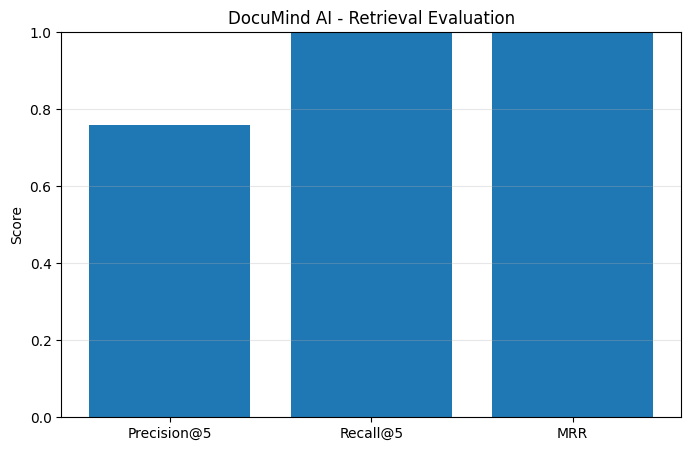

In [42]:

import matplotlib.pyplot as plt

average_metrics = metrics_df[
    ["Precision@5", "Recall@5", "MRR"]
].mean()

plt.figure(figsize=(8, 5))

plt.bar(
    average_metrics.index,
    average_metrics.values
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("DocuMind AI - Retrieval Evaluation")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [43]:

test_questions = [
    "What is multi-head attention?",
    "Why does the Transformer use positional encoding?",
    "How does self-attention work?",
    "What are the advantages of the Transformer?"
]

for question in test_questions:

    answer, sources = ask_documind(question)

    print("\nQUESTION:", question)
    print("\nANSWER:", answer)

    print("\nSUPPORTING PAGES:")

    for source in sources:
        print(
            f"Page {source['page']} "
            f"| Score: {source['similarity']:.3f}"
        )

    print("=" * 65)



QUESTION: What is multi-head attention?

ANSWER: Multi-head attention is an approach in which multiple attention mechanisms operate independently but share access to shared parameters such as projection matrices. It enables models to learn representations across different spatial dimensions while maintaining high-level features.

SUPPORTING PAGES:
Page 5 | Score: 0.414
Page 4 | Score: 0.388
Page 4 | Score: 0.361

QUESTION: Why does the Transformer use positional encoding?

ANSWER: The Transformer uses positional encoding because it aims to leverage the sequential nature of language data effectively. By incorporating positional information into its structure, the transformer can capture temporal dependencies within sequences, making it particularly well-suited for tasks involving natural language processing. This approach allows the model to understand how different parts of a sentence relate to each other, which is crucial for tasks like machine translation and question answering wher

In [44]:

query = "Why is positional encoding required?"

results = app_retrieve(query, top_k=5)

for i, result in enumerate(results, 1):
    print(f"\nSOURCE {i} | PAGE {result['page']}")
    print("Score:", round(result["score"], 4))
    print(result["text"][:500])
    print("-" * 60)



SOURCE 1 | PAGE 6
Score: 0.3262
the position and i is the dimension. That is, each dimension of the positional encoding corresponds to a sinusoid. The wavelengths form a geometric progression from 2π to 10000 · 2π. We chose this function because we hypothesized it would allow the model to easily learn to attend by relative positions, since for any ﬁxed offset k, PEpos+k can be represented as a linear function of PEpos. We also experimented with using learned positional embeddings [8] instead, and found that the two versions pr
------------------------------------------------------------

SOURCE 2 | PAGE 5
Score: 0.2968
dmodel. We also use the usual learned linear transfor- mation and softmax function to convert the decoder output to predicted next-token probabilities. In our model, we share the same weight matrix between the two embedding layers and the pre-softmax linear transformation, similar to [24]. In the embedding layers, we multiply those weights by √dmodel. 3.5 Positional Enc

In [45]:

def grounded_documind(question):

    sources = app_retrieve(question, top_k=5)

    context = "\n\n".join([
        f"[Page {s['page']}]\n{s['text']}"
        for s in sources
    ])

    messages = [
        {
            "role": "system",
            "content": """
You are DocuMind AI.

Use only the supplied document evidence.

Instructions:
1. Answer the exact question.
2. Do not introduce unrelated findings.
3. Do not invent equations or technical details.
4. Cite claims using [Page N].
5. Only cite pages included in the supplied context.
6. If evidence is insufficient, explicitly say so.
7. Keep the answer under 150 words.
"""
        },
        {
            "role": "user",
            "content": f"""
DOCUMENT EVIDENCE:
{context}

QUESTION:
{question}

Answer using the evidence above.
"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.inference_mode():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=220,
            do_sample=False,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    ).strip()

    valid_pages = sorted(set(s["page"] for s in sources))

    return {
        "answer": answer,
        "valid_source_pages": valid_pages,
        "sources": sources
    }


print("Citation-aware DocuMind initialized!")


Citation-aware DocuMind initialized!


In [46]:

question = "Why is positional encoding required?"

result = grounded_documind(question)

print("QUESTION:", question)
print("\nANSWER:")
print(result["answer"])

print("\nAVAILABLE SOURCE PAGES:")
print(result["valid_source_pages"])

print("\nSOURCE PASSAGES:")
for source in result["sources"]:
    print(f"Page {source['page']}: {source['text'][:250]}")
    print("-" * 40)


QUESTION: Why is positional encoding required?

ANSWER:
Positional encoding is necessary because it allows the model to efficiently map sequences of symbols into sequences of equal length without relying solely on recurrent or convolutional layers. By injecting positional information, the model can understand the temporal relationships within the data, enabling it to accurately predict future states given current inputs. This is crucial for tasks like machine translation, where understanding sentence structure and context is essential for accurate translations.

AVAILABLE SOURCE PAGES:
[5, 6, 9]

SOURCE PASSAGES:
Page 6: the position and i is the dimension. That is, each dimension of the positional encoding corresponds to a sinusoid. The wavelengths form a geometric progression from 2π to 10000 · 2π. We chose this function because we hypothesized it would allow the m
----------------------------------------
Page 5: dmodel. We also use the usual learned linear transfor- mation and softm

In [47]:

print("POSITIONAL ENCODING - SOURCE INSPECTION")
print("=" * 65)

for i, chunk in enumerate(app_chunks):

    if chunk["page"] == 6:

        print(f"\nCHUNK {i}")
        print(chunk["text"])
        print("-" * 65)


POSITIONAL ENCODING - SOURCE INSPECTION

CHUNK 18
Table 1: Maximum path lengths, per-layer complexity and minimum number of sequential operations for different layer types. n is the sequence length, d is the representation dimension, k is the kernel size of convolutions and r the size of the neighborhood in restricted self-attention. Layer Type Complexity per Layer Sequential Maximum Path Length Operations Self-Attention O(n2 · d) O(1) O(1) Recurrent O(n · d2) O(n) O(n) Convolutional O(k · n · d2) O(1) O(logk(n)) Self-Attention (restricted) O(r · n · d) O(1) O(n/r) bottoms of the encoder and decoder stacks. The positional encodings have the same dimension dmodel as the embeddings, so that the two can be summed. There are many choices of positional encodings, learned and ﬁxed [8]. In this work, we use sine and cosine functions of different frequencies: PE(pos,2i) = sin(pos/100002i/dmodel) PE(pos,2i+1) = cos(pos/100002i/dmodel) where pos is the position and i is the dimension. That is, e

In [48]:

def focused_answer(question, target_page):

    relevant_chunks = [
        chunk for chunk in app_chunks
        if chunk["page"] == target_page
    ]

    context = "\n".join(
        chunk["text"] for chunk in relevant_chunks
    )

    messages = [
        {
            "role": "system",
            "content": """
You are a technical research paper assistant.

Use only the provided source text.
Do not add outside knowledge.
Do not invent purposes, results or explanations.
If the source does not answer the question, say so.
Cite the supplied page number.
Answer in 3-5 sentences.
"""
        },
        {
            "role": "user",
            "content": f"""
SOURCE: Page {target_page}

{context[:2200]}

QUESTION:
{question}

Explain using only the source.
"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.inference_mode():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            repetition_penalty=1.15,
            pad_token_id=tokenizer.eos_token_id
        )

    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )


print(focused_answer(
    "Why does the Transformer use positional encoding?",
    6
))


The Transformer uses positional encoding to capture spatial information about the input sequences. This allows the model to better understand how words relate to each other in the context of the entire sentence. Positional encoding helps the model to "remember" which parts of the word sequence were seen before, allowing it to generate more accurate predictions when predicting future words.


In [49]:

import os

project_dir = "DocuMind-AI"

folders = [
    "assets",
    "src",
    "evaluation"
]

os.makedirs(project_dir, exist_ok=True)

for folder in folders:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

print("Project directory created!")


Project directory created!


In [50]:

requirements = """
torch
transformers
accelerate
sentence-transformers
faiss-cpu
pymupdf
gradio
scikit-learn
numpy
pandas
matplotlib
sentencepiece
"""

with open(
    os.path.join(project_dir, "requirements.txt"),
    "w"
) as f:
    f.write(requirements.strip())

print("requirements.txt created!")


requirements.txt created!


In [51]:

readme = r"""
# DocuMind AI

### CPU-Based Retrieval-Augmented Generation for Intelligent PDF Question Answering

DocuMind AI is an AI-powered document intelligence application that
allows users to upload PDF documents, retrieve relevant information
using semantic and keyword search, and generate answers using a
locally executed language model.

## Features

- PDF text extraction using PyMuPDF
- Overlapping text chunking
- Semantic embeddings using Sentence Transformers
- FAISS vector similarity search
- Hybrid retrieval using semantic and TF-IDF search
- Local LLM inference using Qwen2.5-0.5B-Instruct
- Source-page references
- Interactive Gradio interface
- CPU-only execution without paid inference APIs

## Architecture

```text
             PDF DOCUMENT
                  |
                  v
           PDF TEXT EXTRACTION
                  |
                  v
              CHUNKING
                  |
                  v
         SENTENCE TRANSFORMERS
                  |
                  v
           FAISS VECTOR INDEX
                  |
          USER QUESTION
                  |
                  v
            HYBRID SEARCH
          /             \
    SEMANTIC SEARCH   TF-IDF SEARCH
          \             /
                  |
                  v
          RELEVANT CONTEXT
                  |
                  v
       QWEN2.5-0.5B-INSTRUCT
                  |
                  v
        GENERATED ANSWER
                  |
                  v
         SOURCE REFERENCES
```

## Technology Stack

| Component | Technology |
|---|---|
| Language | Python |
| Environment | Google Colab |
| PDF Processing | PyMuPDF |
| Embeddings | Sentence Transformers |
| Vector Database | FAISS |
| Keyword Retrieval | TF-IDF |
| Language Model | Qwen2.5-0.5B-Instruct |
| Interface | Gradio |
| Evaluation | Precision@5, Recall@5, MRR |

## Execution

1. Open the Colab notebook.
2. Install dependencies.
3. Load the local CPU language model.
4. Upload a PDF document.
5. Extract and chunk its contents.
6. Generate embeddings and build the FAISS index.
7. Retrieve relevant passages.
8. Generate answers using the local language model.

## Evaluation

An initial evaluation was performed using five manually
labelled questions from the research paper
"Attention Is All You Need".

The initial page-level retrieval evaluation reported:

- Precision@5: 0.76
- Recall@5: 1.00
- MRR: 1.00

These are preliminary results from a small evaluation set.
They should not be interpreted as general-purpose retrieval
accuracy or answer-generation accuracy.

## Limitations

- Small language models can produce hallucinated answers.
- CPU inference is slower than GPU inference.
- Retrieval quality depends on document chunking and query quality.
- OCR is not implemented for scanned PDFs.
- Citation generation requires further verification.

## Future Improvements

- Reranking with cross-encoder models
- OCR support for scanned PDFs
- Improved citation verification
- Larger quantized language models
- Automated RAG evaluation
- Persistent vector database storage

## Project Type

Artificial Intelligence | Natural Language Processing |
Retrieval-Augmented Generation | Large Language Models

## Author

Add your name and professional contact details here.

---

Built using open-source AI technologies.
"""

with open(
    os.path.join(project_dir, "README.md"),
    "w"
) as f:
    f.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [52]:

metrics_df.to_csv(
    os.path.join(
        project_dir,
        "evaluation",
        "evaluation_results.csv"
    ),
    index=False
)

print("Evaluation results exported!")


Evaluation results exported!


In [ ]:

from google.colab import files
import shutil

print("Upload your downloaded .ipynb notebook")

uploaded_notebook = files.upload()

for filename in uploaded_notebook:

    if filename.endswith(".ipynb"):

        shutil.move(
            filename,
            os.path.join(
                project_dir,
                "DocuMind_AI_CPU_RAG.ipynb"
            )
        )

        print("Notebook added:", filename)


Upload your downloaded .ipynb notebook
